# Prática 4: AutoML versus meta-aprendizagem em regressão desbalanceada

Uso o mesmo protocolo das Práticas 1 a 3: 30 datasets de regressão desbalanceada,
SERA (menor é melhor) e as mesmas dez partições (KFold com embaralhamento e semente 42).
O AutoML recebe só o treino de cada fold.

As execuções pesadas estão nos scripts `executar_baselines.py`, `executar_warmstart.py`
e `executar_automl.py`, chamados por `rodar_tudo.sh`. Este notebook só lê os resultados
brutos de `resultados/` e faz as análises.

In [1]:
import json, sys, time
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import friedmanchisquare, spearmanr, studentized_range
import scikit_posthocs as sp

import comum as c
sys.path.insert(0, str(c.BASE / 'codigo'))
from gerar_X import extrair_meta_features
from meta_por_fold import carregar_meta_por_fold
import mtl
from scipy.stats import wilcoxon
from statsmodels.stats.multitest import multipletests

R = c.SAIDA
FIG = R / 'figuras'; FIG.mkdir(exist_ok=True)
DATASETS = c.datasets()
pd.set_option('display.width', 160)
print(json.dumps(c.ambiente(), indent=1))

{
 "cpu": "Apple M2",
 "nucleos": 8,
 "memoria_gb": 8.0,
 "python": "3.11.18",
 "sistema": "macOS-27.2.1-arm64-arm-64bit"
}


## 1. Resultados brutos por fold

In [2]:
base = pd.read_csv(R / 'base_por_fold.csv')
desreg = pd.read_csv(R / 'desreg_por_fold.csv')
ws = pd.read_csv(R / 'warmstart_por_fold.csv')
# segundos_iniciais já inclui, por fold, extrair Xestendido do treino e achar os vizinhos
ws['segundos'] = ws.segundos_busca + ws.segundos_final + ws.segundos_iniciais
print('folds do Warm-start reaproveitados da versão 1 (mesmas iniciais):', int(ws.reaproveitado.sum()), 'de', len(ws))

linhas = []
for arq in sorted((R / 'automl').glob('*.jsonl')):
    linhas += [json.loads(l) for l in arq.read_text().splitlines()]
automl = pd.DataFrame(linhas)
falhas = automl[automl.erro.notna()]
automl = automl[automl.erro.isna()].drop_duplicates(['sistema', 'orcamento', 'dataset', 'fold'], keep='last')
automl['metodo'] = automl.sistema + '_' + automl.orcamento.astype(str) + 's'
print('falhas registradas (reexecutadas depois):', len(falhas))
display(automl.groupby(['sistema', 'orcamento']).agg(execucoes=('sera', 'size'),
        segundos_medios=('segundos', 'mean'), segundos_max=('segundos', 'max')).round(1))
assert (automl.groupby('metodo').size() == 300).all(), 'há execuções faltando'

folds do Warm-start reaproveitados da versão 1 (mesmas iniciais): 203 de 300
falhas registradas (reexecutadas depois): 28


execucoes  segundos_medios  segundos_max
sistema    orcamento                                          
autogluon  5                300              8.3          26.7
           30               300             26.2          35.8
           120              300             65.4         128.6
flaml      5                300              5.7          24.2
           30               300             31.0          54.9
flaml_meta 5                300              8.8          73.3
           30               300             32.6          82.2
           120              300            111.4         178.6

A matriz P das práticas anteriores já usa essas partições, mas reexecutei os seis
regressores aqui, junto com o AutoML, para que tempos e perdas venham do mesmo ambiente.
A célula abaixo compara o resultado com a P original.

In [3]:
P = base.pivot_table(index='dataset', columns='metodo', values='sera').loc[DATASETS, c.ALGORITMOS]
P_antiga = pd.read_csv(c.META / 'P.csv', index_col=0).loc[DATASETS, c.ALGORITMOS]
dif = (P / P_antiga - 1).abs()
print('diferença relativa mediana com a P da Prática 1:', f'{dif.stack().median():.2e}',
      '| máxima:', f'{dif.stack().max():.3f}')
print('o melhor algoritmo coincide em', int((P.idxmin(axis=1) == P_antiga.idxmin(axis=1)).sum()), 'de 30 datasets')
Rk = P.rank(axis=1)

diferença relativa mediana com a P da Prática 1: 2.50e-07 | máxima: 0.184
o melhor algoritmo coincide em 30 de 30 datasets


## 2. Métodos comparados

1. Melhor médio: regressor de melhor rank médio nos outros 29 datasets, com configuração padrão.
2. MtL: Abordagem 2 da Prática 1 (RF sobre R, com Xbase, em leave-one-dataset-out), top-1.
   Xestendido não trouxe ganho significativo na Prática 2. O alvo é descrito pelo Xbase
   calculado só no treino de cada fold (`meta_por_fold.py`), então a recomendação é por fold.
3. Warm-start: SMBO da Prática 3 (Xestendido, k=3, T=20), avaliando só no treino do fold.
   Os vizinhos também usam o Xestendido do treino do fold.

Na versão 1 desta prática, o alvo era descrito por Xbase e Xestendido calculados no dataset
inteiro, incluindo o fold de teste. Os resultados dessa versão estão em `resultados/versao_1/`.
4. AutoML: FLAML (com e sem meta-conhecimento) e AutoGluon, com 5, 30 e 120 s por fold.
5. Oráculo: melhor dos seis regressores de P no dataset. É uma referência, não um método.

Por causa do tema da minha pesquisa, incluí também a DESReg (seleção dinâmica sobre o pool
de bagging dos seis regressores), com a competência padrão e com uma ponderada pela relevância (`phi`).

In [4]:
Xbase = pd.read_csv(c.META / 'X.csv', index_col=0).loc[DATASETS]   # offline: os outros 29 datasets
meta_fold = carregar_meta_por_fold()
assert len(meta_fold) == 300, 'faltam meta-características por fold'
recs = mtl.recomendacoes_por_fold(Xbase, Rk, meta_fold)
rec = recs.pivot(index='dataset', columns='fold', values='alg').loc[DATASETS]
print('datasets em que a recomendação varia entre folds:', int((rec.nunique(axis=1) > 1).sum()))
rec_v1 = pd.read_csv(R / 'versao_1' / 'todos_por_fold.csv').query("metodo == 'MtL'")
rec_v1 = base.merge(rec_v1[['dataset', 'fold', 'sera']], on=['dataset', 'fold', 'sera']).groupby('dataset').metodo.first()
print('folds em que a recomendação mudou em relação à versão 1:', int((rec.ne(rec_v1.reindex(DATASETS), axis=0)).sum().sum()), 'de 300')
rec_moda = rec.mode(axis=1)[0].rename('MtL (moda)')
# custo de extrair Xbase no dataset inteiro: parte do custo offline (29 outros datasets)
t_xbase = {}
for d in DATASETS:
    t0 = time.perf_counter(); extrair_meta_features(c.DADOS / f'{d}.csv'); t_xbase[d] = time.perf_counter() - t0
t_xbase = pd.Series(t_xbase)
melhor_medio = pd.Series({d: Rk.drop(index=d).mean().idxmin() for d in DATASETS}, name='Melhor_medio')
display(pd.concat([melhor_medio, rec_moda, P.idxmin(axis=1).rename('Oraculo')], axis=1).T)
display(rec_moda.value_counts())

datasets em que a recomendação varia entre folds: 5
folds em que a recomendação mudou em relação à versão 1: 8 de 300


,a1,a2,a3,a7,abalone,acceleration,airfoild,analcatdata_apnea3,available_power,boston,...,lungcancer_shedden,maximal_torque,meta,mortgage,pdgfr,sensory,space_ga,treasury,triazines,wine_quality
Melhor_medio,RF,RF,RF,RF,RF,RF,RF,RF,RF,RF,...,RF,RF,RF,RF,RF,RF,RF,RF,RF,RF
MtL (moda),RF,RF,GB,RF,RF,GB,RF,RF,GB,RF,...,RF,RF,GB,RF,RF,RF,RF,GB,GB,RF
Oraculo,GB,RF,RF,RF,RF,RF,DT,RF,RF,GB,...,Linear,GB,Linear,Linear,GB,RF,SVR,Linear,RF,RF


MtL (moda)
RF    22
GB     8
Name: count, dtype: int64

In [5]:
def por_fold(algs, nome):
    if isinstance(algs, pd.DataFrame):   # um algoritmo por (dataset, fold)
        m = base.merge(algs[['dataset', 'fold', 'alg']], on=['dataset', 'fold'])
    else:
        m = base.merge(algs.rename('alg').reset_index().rename(columns={'index': 'dataset'}), on='dataset')
    m = m[m.metodo == m.alg].assign(metodo=nome)
    return m[['dataset', 'fold', 'metodo', 'sera', 'segundos']]

oraculo = P.idxmin(axis=1)
folds = pd.concat([
    por_fold(melhor_medio, 'Melhor_medio'),
    por_fold(recs, 'MtL'),
    ws.assign(metodo='Warm-start')[['dataset', 'fold', 'metodo', 'sera', 'segundos']],
    desreg[['dataset', 'fold', 'metodo', 'sera', 'segundos']],
    automl[['dataset', 'fold', 'metodo', 'sera', 'segundos']],
    por_fold(oraculo, 'Oraculo'),
])
# custo online da recomendação, por fold: Xbase do treino + meta-modelo
extra = recs.set_index(['dataset', 'fold'])[['segundos_meta_caracteristicas', 'segundos_meta_modelo']].sum(axis=1)
msk = folds.metodo == 'MtL'
folds.loc[msk, 'segundos'] += extra.reindex(pd.MultiIndex.from_frame(folds.loc[msk, ['dataset', 'fold']])).to_numpy()
folds.to_csv(R / 'todos_por_fold.csv', index=False)

L = folds.pivot_table(index='dataset', columns='metodo', values='sera').loc[DATASETS]
TEMPO = folds.pivot_table(index='dataset', columns='metodo', values='segundos').loc[DATASETS]
METODOS_FIXOS = ['Melhor_medio', 'MtL', 'Warm-start', 'DESReg', 'DESReg_phi']
AUTOML = sorted(automl.metodo.unique(), key=lambda m: (m.split('_')[0], int(m.split('_')[-1][:-1]), m))

## 3. Análise 1: desempenho

In [6]:
# Perda relativa ao melhor resultado observado no dataset (entre todos os métodos e o oráculo)
melhor = L.min(axis=1)
REL = L.div(melhor, axis=0) - 1
resumo = pd.DataFrame({'perda_rel_media': REL.mean(), 'perda_rel_mediana': REL.median(),
                       'rank_medio': L.drop(columns='Oraculo').rank(axis=1).mean(),
                       'vitorias': (L.drop(columns='Oraculo').rank(axis=1) == 1).sum(),
                       'segundos_por_fold': TEMPO.mean()}).sort_values('rank_medio')
display(resumo.round(3))
resumo.to_csv(R / 'resumo_metodos.csv')
L.to_csv(R / 'sera_por_dataset.csv'); REL.to_csv(R / 'perda_relativa_por_dataset.csv')

,perda_rel_media,perda_rel_mediana,rank_medio,vitorias,segundos_por_fold
metodo,,,,,
autogluon_120s,0.210,0.020,4.333,8.0,65.434
autogluon_30s,0.413,0.123,5.033,1.0,26.169
Warm-start,2.009,0.279,5.867,0.0,63.159
flaml_meta_120s,1.457,0.159,6.433,3.0,111.446
Melhor_medio,2.105,0.300,6.567,0.0,1.496
flaml_meta_30s,1.485,0.178,6.783,3.0,32.613
MtL,2.118,0.319,6.867,0.0,1.373
flaml_meta_5s,1.516,0.288,7.083,1.0,8.756
flaml_30s,0.410,0.195,7.317,1.0,31.013


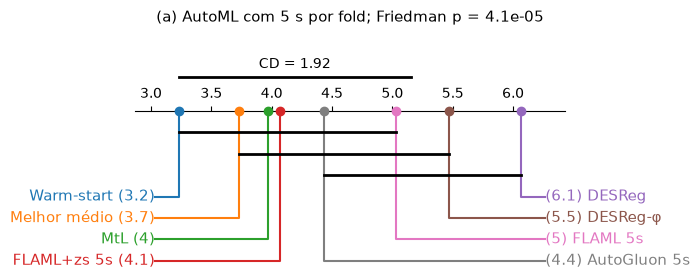

5s: p(MtL vs AutoML): {'autogluon_5s': np.float64(0.9959), 'flaml_5s': np.float64(0.6961), 'flaml_meta_5s': np.float64(1.0)}


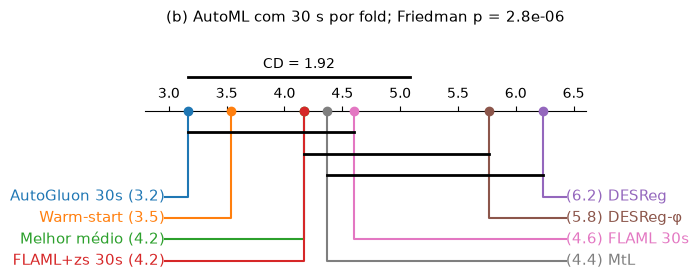

30s: p(MtL vs AutoML): {'autogluon_30s': np.float64(0.5527), 'flaml_30s': np.float64(1.0), 'flaml_meta_30s': np.float64(1.0)}


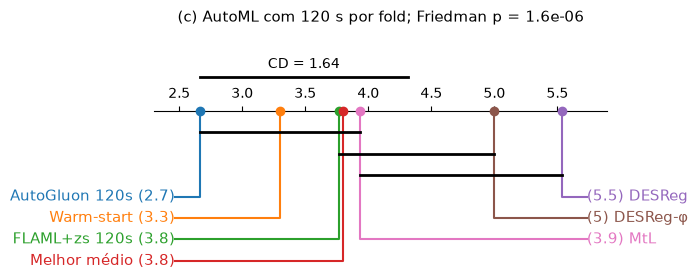

120s: p(MtL vs AutoML): {'autogluon_120s': np.float64(0.2582), 'flaml_meta_120s': np.float64(0.9999)}


,orcamento,metodos,friedman,p,cd
0,5,8,31.9648,0.0,1.9169
1,30,8,38.1584,0.0,1.9169
2,120,7,37.2000,0.0,1.6445


In [7]:
ROT = {'Melhor_medio': 'Melhor médio', 'MtL': 'MtL', 'Warm-start': 'Warm-start',
       'DESReg': 'DESReg', 'DESReg_phi': 'DESReg-φ'}
def rotulo(m):
    if m in ROT: return ROT[m]
    s, o = m.rsplit('_', 1)
    return {'flaml': 'FLAML', 'flaml_meta': 'FLAML+zs', 'autogluon': 'AutoGluon'}[s] + f' {o}'

testes = []
for orc in [5, 30, 120]:
    cols = METODOS_FIXOS + [m for m in AUTOML if m.endswith(f'_{orc}s')]
    tab = L[cols]
    est, p = friedmanchisquare(*[tab[col] for col in cols])
    k, n = len(cols), len(tab)
    cd = studentized_range.ppf(0.95, k, np.inf) / np.sqrt(2) * np.sqrt(k * (k + 1) / (6 * n))
    pv = sp.posthoc_nemenyi_friedman(tab.to_numpy()); pv.index = pv.columns = cols
    ranks = tab.rank(axis=1).mean()
    testes.append(dict(orcamento=orc, metodos=k, friedman=est, p=p, cd=cd))
    plt.figure(figsize=(7, 2.9))
    sp.critical_difference_diagram(ranks.rename(rotulo), pv.rename(index=rotulo, columns=rotulo),
                                   label_props={'fontsize': 11}, text_h_margin=0.2)
    ax = plt.gca(); ini = ranks.min()
    ax.plot([ini, ini + cd], [1.6, 1.6], color='black', lw=2)
    ax.text(ini + cd / 2, 2.0, f'CD = {cd:.2f}', ha='center', fontsize=10); ax.set_ylim(top=3.0)
    plt.title(f'({"abc"[[5, 30, 120].index(orc)]}) AutoML com {orc} s por fold; Friedman p = {p:.2g}', fontsize=11, pad=18)
    plt.tight_layout(); plt.savefig(FIG / f'cd_{orc}s.pdf', bbox_inches='tight'); plt.show()
    pv.to_csv(R / f'nemenyi_{orc}s.csv')
    print(f'{orc}s: p(MtL vs AutoML):', {m: round(pv.loc['MtL', m], 4) for m in cols if m not in METODOS_FIXOS})
testes = pd.DataFrame(testes); testes.to_csv(R / 'friedman.csv', index=False); display(testes.round(4))

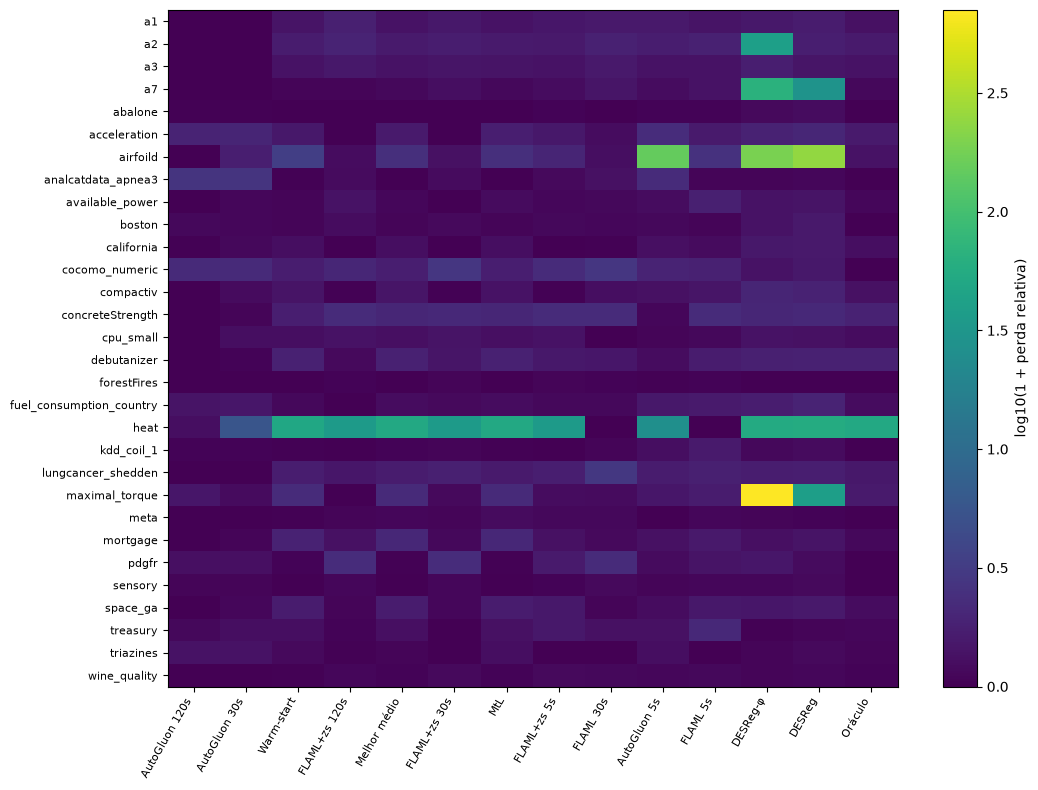

In [8]:
# Dataset a dataset: perda relativa de cada método (heatmap)
ordem = resumo.index.tolist()
fig, ax = plt.subplots(figsize=(11, 8))
im = ax.imshow(np.log10(1 + REL[ordem].to_numpy()), aspect='auto', cmap='viridis')
ax.set_xticks(range(len(ordem)), [rotulo(m) if m != 'Oraculo' else 'Oráculo' for m in ordem], rotation=60, ha='right', fontsize=8)
ax.set_yticks(range(len(DATASETS)), DATASETS, fontsize=8)
plt.colorbar(im, label='log10(1 + perda relativa)'); plt.tight_layout()
plt.savefig(FIG / 'perda_por_dataset.pdf', bbox_inches='tight'); plt.show()

## 4. Análise 2: desempenho e custo

{'MtL': '0.26 h (núcleo)', 'Warm-start': '8.82 h (núcleo)'}


,segundos_por_fold,nucleo_segundos_por_fold,perda_rel_media,perda_rel_mediana,rank_medio
MtL,1.373,1.373,2.118,0.319,6.867
Melhor_medio,1.496,1.496,2.105,0.300,6.567
flaml_5s,5.739,11.479,0.484,0.434,8.350
autogluon_5s,8.334,16.667,6.216,0.308,7.567
flaml_meta_5s,8.756,17.512,1.516,0.288,7.083
autogluon_30s,26.169,52.338,0.413,0.123,5.033
flaml_30s,31.013,62.027,0.410,0.195,7.317
DESReg_phi,31.833,31.833,35.525,0.490,9.100
DESReg,31.839,31.839,12.561,0.551,9.700
flaml_meta_30s,32.613,65.227,1.485,0.178,6.783


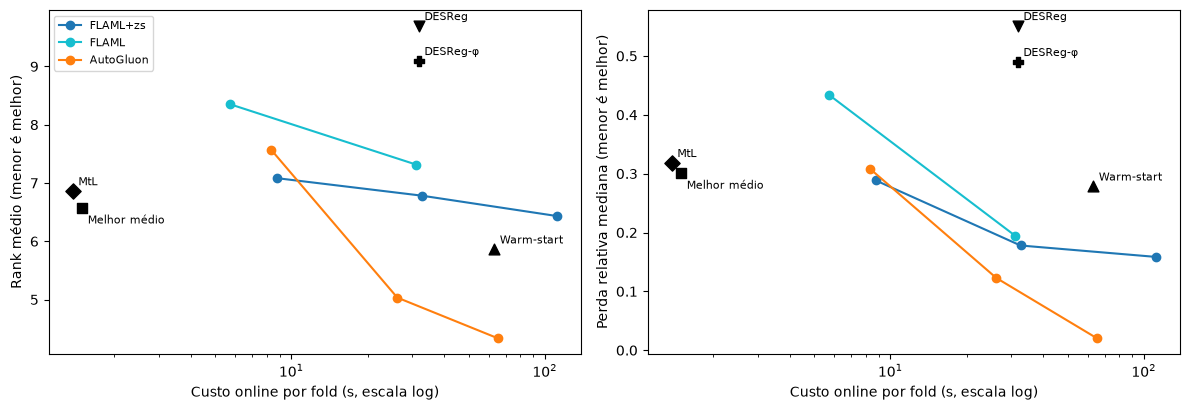

In [9]:
# Unidades. Todos os tempos foram medidos em relógio (time.perf_counter).
# Regressores de P, extração de meta-características, matriz da Prática 3, MtL e Warm-start rodam
# em um processo de 1 thread: núcleo-segundos ≈ segundos de relógio. (O meta-modelo RF da MtL usa
# n_jobs=-1 sobre 29 linhas e leva menos de 1 s; tratei como 1 núcleo.)
# Cada execução de AutoML tinha 2 CPUs reservadas: 2 × relógio é o limite superior de núcleo-segundos.
# Nenhum dos dois números mede CPU efetivamente usada (não registrei tempo de CPU do processo).
NUCLEOS = {m: (2 if m in AUTOML else 1) for m in TEMPO.columns}

# Custo offline (núcleo-segundos), do conjunto das práticas:
#  * MtL: construir P (6 regressores × 10 folds × 30 datasets, medido aqui) e Xbase dos datasets
#  * Warm-start: matriz de perdas 60 × 30 da Prática 3 e extração de Xestendido (Prática 2)
custo_ext = pd.read_csv(c.BASE / 'pratica-02' / 'resultados' / 'custo_extracao.csv')
custo_ext = custo_ext[custo_ext.fase != 'nulo']           # distribuições nulas são diagnóstico, não descritor
t_xest = custo_ext.groupby('dataset').segundos.sum().reindex(DATASETS)
tempo_p3 = json.loads((c.P3 / 'tempo_matriz.json').read_text())
offline = {'MtL': base.segundos.sum() + t_xbase.sum(),
           'Warm-start': tempo_p3['segundos_ajustes'] + t_xest.sum()}
print({k: f'{v/3600:.2f} h (núcleo)' for k, v in offline.items()})

custo = pd.DataFrame({'segundos_por_fold': TEMPO.drop(columns='Oraculo').mean(),
                      'nucleo_segundos_por_fold': (TEMPO.drop(columns='Oraculo') * pd.Series(NUCLEOS)).mean(),
                      'perda_rel_media': REL.drop(columns='Oraculo').mean(),
                      'perda_rel_mediana': REL.drop(columns='Oraculo').median(),
                      'rank_medio': L.drop(columns='Oraculo').rank(axis=1).mean()})
display(custo.sort_values('segundos_por_fold').round(3))
custo.to_csv(R / 'custo_desempenho.csv')

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for eixo, y, nome in [(ax[0], 'rank_medio', 'Rank médio (menor é melhor)'), (ax[1], 'perda_rel_mediana', 'Perda relativa mediana (menor é melhor)')]:
    for sis, cor in [('flaml_meta', 'C0'), ('flaml', 'C9'), ('autogluon', 'C1')]:
        sub = custo.loc[[m for m in AUTOML if m.rsplit('_', 1)[0] == sis]].sort_values('segundos_por_fold')
        eixo.plot(sub.segundos_por_fold, sub[y], 'o-', color=cor, label=rotulo(sub.index[0]).split()[0])
    for m, mk in zip(METODOS_FIXOS, ['s', 'D', '^', 'v', 'P']):
        eixo.scatter(custo.loc[m, 'segundos_por_fold'], custo.loc[m, y], marker=mk, s=60, color='k')
        eixo.annotate(rotulo(m), (custo.loc[m, 'segundos_por_fold'], custo.loc[m, y]), xytext=(4, -11 if m == 'Melhor_medio' else 4), textcoords='offset points', fontsize=8)
    eixo.set_xscale('log'); eixo.set_xlabel('Custo online por fold (s, escala log)'); eixo.set_ylabel(nome)
ax[0].legend(fontsize=8); plt.tight_layout(); plt.savefig(FIG / 'custo_desempenho.pdf', bbox_inches='tight'); plt.show()

In [10]:
# Com que orçamento o AutoML supera a MtL? Por dataset: menor orçamento em que a SERA média do AutoML < a da MtL.
supera = {}
for sis in ['flaml_meta', 'flaml', 'autogluon']:
    cols = [m for m in AUTOML if m.rsplit('_', 1)[0] == sis]
    for alvo in ['MtL', 'Warm-start']:
        primeiro = L[cols].lt(L[alvo], axis=0).idxmax(axis=1).where(L[cols].lt(L[alvo], axis=0).any(axis=1), 'nunca')
        supera[(sis, alvo)] = primeiro.value_counts().reindex(cols + ['nunca'], fill_value=0)
display(pd.DataFrame(supera).fillna(0).astype(int))

# Ponto de equilíbrio do custo offline: menor n de datasets novos com offline + online_sol × n ≤ online_AutoML × n.
# Duas unidades: relógio (como na versão 1) e núcleo-segundos (AutoML × 2). A comparação defensável
# é com AutoML de desempenho equivalente; contra AutoML melhores, a economia troca qualidade por custo.
eq = []
for sol in ['MtL', 'Warm-start']:
    for m in AUTOML:
        linha = dict(solucao=sol, automl=rotulo(m),
                     automl_melhor_em_rank=custo.loc[m, 'rank_medio'] < custo.loc[sol, 'rank_medio'])
        for unid, col in [('relogio', 'segundos_por_fold'), ('nucleo', 'nucleo_segundos_por_fold')]:
            dif = (custo.loc[m, col] - custo.loc[sol, col]) * c.FOLDS          # por dataset (10 folds)
            linha[f'economia_s_{unid}'] = dif
            linha[f'equilibrio_{unid}'] = int(np.ceil(offline[sol] / dif)) if dif > 0 else np.nan
        eq.append(linha)
eq = pd.DataFrame(eq); display(eq.round(1)); eq.to_csv(R / 'ponto_equilibrio.csv', index=False)

flaml_meta            flaml            autogluon           
                       MtL Warm-start   MtL Warm-start       MtL Warm-start
autogluon_120s           0          0     0          0         0          2
autogluon_30s            0          0     0          0        10          8
autogluon_5s             0          0     0          0        10         10
flaml_30s                0          0     5          3         0          0
flaml_5s                 0          0    12         10         0          0
flaml_meta_120s          2          2     0          0         0          0
flaml_meta_30s           2          3     0          0         0          0
flaml_meta_5s           16         14     0          0         0          0
nunca                   10         11    13         17        10         10

,solucao,automl,automl_melhor_em_rank,economia_s_relogio,equilibrio_relogio,economia_s_nucleo,equilibrio_nucleo
0,MtL,AutoGluon 5s,False,69.6,14.0,152.9,7.0
1,MtL,AutoGluon 30s,True,248.0,4.0,509.7,2.0
2,MtL,AutoGluon 120s,True,640.6,2.0,1295.0,1.0
3,MtL,FLAML 5s,False,43.7,22.0,101.1,10.0
4,MtL,FLAML+zs 5s,False,73.8,13.0,161.4,6.0
5,MtL,FLAML 30s,False,296.4,4.0,606.5,2.0
6,MtL,FLAML+zs 30s,True,312.4,3.0,638.5,2.0
7,MtL,FLAML+zs 120s,True,1100.7,1.0,2215.2,1.0
8,Warm-start,AutoGluon 5s,False,-548.3,NaN,-464.9,NaN
9,Warm-start,AutoGluon 30s,True,-369.9,NaN,-108.2,NaN


## 5. Análise 3: o que o AutoML escolheu

In [11]:
FAMILIA = {'rf': 'RF', 'RandomForestMSE': 'RF', 'RandomForest': 'RF', 'lgbm': 'GB', 'xgboost': 'GB', 'xgb_limitdepth': 'GB',
           'catboost': 'GB', 'LightGBM': 'GB', 'LightGBMXT': 'GB', 'LightGBMLarge': 'GB', 'CatBoost': 'GB', 'XGBoost': 'GB',
           'extra_tree': 'ExtraTrees', 'ExtraTreesMSE': 'ExtraTrees', 'sgd': 'Linear', 'LinearModel': 'Linear',
           'KNeighborsUnif': 'KNN', 'KNeighborsDist': 'KNN', 'NeuralNetFastAI': 'Rede neural', 'NeuralNetTorch': 'Rede neural'}
def base_ag(m): return m.split('_BAG')[0].replace('_L1', '')

def familias(r):
    if r.sistema == 'autogluon' and isinstance(r.pesos_ensemble, dict) and r.pesos_ensemble:
        return sorted({FAMILIA.get(base_ag(k), k) for k in r.pesos_ensemble})
    return [FAMILIA.get(base_ag(r.modelo), r.modelo)]
automl['familias'] = automl.apply(familias, axis=1)
def modelo_base(r):
    # AutoGluon: um WeightedEnsemble com um único peso é, na prática, aquele modelo
    if r.sistema != 'autogluon':
        return base_ag(r.modelo)
    if r.ensemble:
        return 'WeightedEnsemble'
    pesos = r.pesos_ensemble if isinstance(r.pesos_ensemble, dict) and r.pesos_ensemble else {r.modelo: 1}
    return base_ag(next(iter(pesos)))
automl['modelo_base'] = automl.apply(modelo_base, axis=1)

display(automl.groupby('metodo').modelo_base.value_counts(normalize=True).unstack(fill_value=0).round(2))
ag = automl[automl.sistema == 'autogluon']
print('AutoGluon: fração de folds com ensemble de >1 modelo:', ag.ensemble.astype(float).groupby(ag.orcamento).mean().round(2).to_dict())
print('AutoGluon: modelos por ensemble (média):', ag.groupby('orcamento').pesos_ensemble.apply(lambda s: np.mean([len(p) if isinstance(p, dict) else 1 for p in s])).round(2).to_dict())

exp = automl.explode('familias')
# fração de folds em que cada família aparece no modelo final (um ensemble pode ter várias)
freq = pd.crosstab([exp.metodo, exp.dataset, exp.fold], exp.familias).clip(upper=1).groupby('metodo').mean()
print('fração de folds em que a família aparece no modelo final:'); display(freq.round(2))
fora_de_P = automl.familias.apply(lambda f: bool(set(f) - set(c.ALGORITMOS))).groupby(automl.metodo).mean()
print('fração de folds com alguma família fora dos 6 algoritmos de P:'); display(fora_de_P.round(2))

concorda = exp.merge(recs[['dataset', 'fold', 'alg']].rename(columns={'alg': 'rec'}), on=['dataset', 'fold']).assign(igual=lambda d: d.familias == d.rec).groupby(['metodo', 'dataset', 'fold']).igual.any().groupby('metodo').mean()
print('fração de folds em que a família recomendada pela MtL aparece no modelo final do AutoML:'); display(concorda.round(2))

modelo_base,CatBoost,ExtraTreesMSE,LightGBM,LightGBMLarge,LightGBMXT,NeuralNetFastAI,NeuralNetTorch,RandomForestMSE,WeightedEnsemble,catboost,extra_tree,lgbm,rf,sgd,xgb_limitdepth,xgboost
metodo,,,,,,,,,,,,,,,,
autogluon_120s,0.02,0.01,0.03,0.01,0.04,0.01,0.04,0.00,0.83,0.00,0.00,0.00,0.00,0.00,0.00,0.00
autogluon_30s,0.00,0.01,0.11,0.01,0.23,0.01,0.04,0.00,0.58,0.00,0.00,0.00,0.00,0.00,0.00,0.00
autogluon_5s,0.01,0.00,0.10,0.00,0.55,0.02,0.00,0.04,0.27,0.00,0.00,0.00,0.00,0.00,0.00,0.00
flaml_30s,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.16,0.03,0.32,0.03,0.06,0.15,0.26
flaml_5s,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.22,0.03,0.42,0.04,0.05,0.02,0.22
flaml_meta_120s,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.05,0.11,0.38,0.04,0.06,0.08,0.27
flaml_meta_30s,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.06,0.12,0.41,0.03,0.05,0.07,0.27
flaml_meta_5s,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.09,0.08,0.46,0.04,0.04,0.06,0.24


AutoGluon: fração de folds com ensemble de >1 modelo: {5: 0.27, 30: 0.58, 120: 0.83}
AutoGluon: modelos por ensemble (média): {5: 1.38, 30: 1.87, 120: 2.38}
fração de folds em que a família aparece no modelo final:


familias,ExtraTrees,GB,Linear,RF,Rede neural
metodo,,,,,
autogluon_120s,0.15,0.84,0.00,0.21,0.65
autogluon_30s,0.11,0.87,0.00,0.21,0.41
autogluon_5s,0.09,0.89,0.00,0.20,0.15
flaml_30s,0.03,0.89,0.06,0.03,0.00
flaml_5s,0.03,0.89,0.05,0.04,0.00
flaml_meta_120s,0.11,0.79,0.06,0.04,0.00
flaml_meta_30s,0.12,0.80,0.05,0.03,0.00
flaml_meta_5s,0.08,0.84,0.04,0.04,0.00


fração de folds com alguma família fora dos 6 algoritmos de P:


metodo
autogluon_120s     0.69
autogluon_30s      0.45
autogluon_5s       0.19
flaml_30s          0.03
flaml_5s           0.03
flaml_meta_120s    0.11
flaml_meta_30s     0.12
flaml_meta_5s      0.08
Name: familias, dtype: float64

fração de folds em que a família recomendada pela MtL aparece no modelo final do AutoML:


metodo
autogluon_120s     0.37
autogluon_30s      0.35
autogluon_5s       0.37
flaml_30s          0.24
flaml_5s           0.24
flaml_meta_120s    0.16
flaml_meta_30s     0.16
flaml_meta_5s      0.19
Name: igual, dtype: float64

In [12]:
# Pré-processamento: o FLAML não faz engenharia de atributos para dados numéricos; o AutoGluon aplica
# seu gerador de atributos automático (todos os 30 datasets são numéricos, então ele só tipa/remove constantes).
# Onde o AutoML mais ganhou da MtL, e o que já sabíamos desses datasets?
ref = 'flaml_meta_120s' if 'flaml_meta_120s' in L else AUTOML[-1]
# AutoGluon a 120 s sozinho: escolher o melhor AutoML por dataset olharia o teste
ganho = (L['MtL'] - L['autogluon_120s']) / L['MtL']
dist = pd.read_csv(c.P3 / 'distancias.csv').query("meta == 'estendido'").set_index('dataset').distancia
p1 = pd.read_csv(c.BASE / 'pratica-01' / 'resultados' / 'avaliacao_por_dataset.csv').query("abordagem == 'Abordagem_2'").set_index('dataset')
tab = pd.DataFrame({'ganho_rel_AutoGluon_120s': ganho,
                    'MtL_acerta_oraculo_frac': rec.eq(oraculo, axis=0).mean(axis=1),
                    'perda_meta_modelo_P1': p1.perda_t1,
                    'distancia_vizinho_P3': dist,
                    'pct_relevante': Xbase.pct_relevante, 'n': Xbase.n_instances, 'p': Xbase.n_features,
                    'oraculo_vs_MtL': L['MtL'] / L['Oraculo'] - 1,
                    'automl_vs_oraculo': L['autogluon_120s'] / L['Oraculo'] - 1}).loc[DATASETS]
display(tab.sort_values('ganho_rel_AutoGluon_120s', ascending=False).round(3))
# Análise exploratória: 5 correlações; corrijo os p-valores por Holm.
cor = []
for col in ['perda_meta_modelo_P1', 'distancia_vizinho_P3', 'pct_relevante', 'n', 'p']:
    rho, p = spearmanr(tab.ganho_rel_AutoGluon_120s, tab[col], nan_policy='omit')
    sem_cal = tab.drop(index='california')
    rho2, p2 = spearmanr(sem_cal.ganho_rel_AutoGluon_120s, sem_cal[col], nan_policy='omit')
    cor.append(dict(caracteristica=col, rho=rho, p=p, rho_sem_california=rho2, p_sem_california=p2))
cor = pd.DataFrame(cor)
cor['p_holm'] = multipletests(cor.p, method='holm')[1]
cor['p_holm_sem_california'] = multipletests(cor.p_sem_california, method='holm')[1]
display(cor.round(3)); cor.to_csv(R / 'spearman_ganho.csv', index=False)
print('Datasets em que o AutoGluon 120 s supera o ORÁCULO dos 6 algoritmos:', int((tab.automl_vs_oraculo < 0).sum()), 'de 30',
      '| ganho mediano sobre o oráculo:', round(float(-tab.automl_vs_oraculo.median()), 3))
tab.to_csv(R / 'ganho_automl_por_dataset.csv')

,ganho_rel_AutoGluon_120s,MtL_acerta_oraculo_frac,perda_meta_modelo_P1,distancia_vizinho_P3,pct_relevante,n,p,oraculo_vs_MtL,automl_vs_oraculo
dataset,,,,,,,,,
heat,0.976,1.0,0.000,4.914,0.090,7400,11,0.000,-0.976
airfoild,0.585,0.0,0.000,7.727,0.107,1503,5,0.740,-0.278
mortgage,0.523,0.0,0.344,0.767,0.101,1049,15,0.826,-0.129
concreteStrength,0.501,0.0,0.027,4.378,0.053,1030,8,0.082,-0.460
debutanizer,0.452,1.0,0.000,5.085,0.100,2394,7,0.000,-0.452
space_ga,0.396,0.0,0.406,370.289,0.056,3107,6,0.326,-0.199
a2,0.384,1.0,0.000,4.852,0.111,198,11,0.000,-0.384
lungcancer_shedden,0.384,0.0,0.116,4.349,0.057,442,24,0.052,-0.352
maximal_torque,0.315,0.0,0.000,2.957,0.072,1802,32,0.352,-0.074


,caracteristica,rho,p,rho_sem_california,p_sem_california,p_holm,p_holm_sem_california
0,perda_meta_modelo_P1,0.088,0.643,0.100,0.605,0.725,0.644
1,distancia_vizinho_P3,-0.172,0.362,-0.191,0.322,0.725,0.644
2,pct_relevante,-0.447,0.013,-0.445,0.016,0.066,0.078
3,n,0.346,0.061,0.355,0.058,0.184,0.175
4,p,-0.445,0.014,-0.445,0.016,0.066,0.078


Datasets em que o AutoGluon 120 s supera o ORÁCULO dos 6 algoritmos: 18 de 30 | ganho mediano sobre o oráculo: 0.083


## 6. Meta-conhecimento do AutoML e sobreposição com os meus datasets

In [13]:
# FLAML com e sem o portfólio zero-shot, no mesmo orçamento
for orc in [5, 30, 120]:
    a, b = f'flaml_meta_{orc}s', f'flaml_{orc}s'
    if a in L and b in L:
        d = (L[b] - L[a]) / L[b]
        print(f'{orc}s: zero-shot melhor em {(d > 0).sum()}/30 datasets; ganho relativo mediano {d.median():+.3f}')

# Quantos estimadores receberam configuração zero-shot efetiva (diferente do ponto estático)?
fm = automl[automl.sistema == 'flaml_meta'].copy()
estaticos = automl[automl.sistema == 'flaml'].set_index(['dataset', 'fold', 'orcamento']).iniciais
def efetivos(r):
    est = estaticos.get((r.dataset, r.fold, r.orcamento))
    if not isinstance(est, dict): return np.nan
    return sum(json.dumps(r.iniciais.get(e), sort_keys=True, default=str) != json.dumps(est.get(e), sort_keys=True, default=str) for e in r.iniciais)
fm['zero_shot_efetivos'] = fm.apply(efetivos, axis=1)
print('estimadores com ponto inicial zero-shot efetivo (média por fold):')
display(fm.groupby('dataset').zero_shot_efetivos.mean().sort_values(ascending=False).head(10))
print('primeiro estimador da busca (sugerido pelo zero-shot):', fm.ordem_estimadores.str[0].value_counts().to_dict())

5s: zero-shot melhor em 19/30 datasets; ganho relativo mediano +0.019
30s: zero-shot melhor em 18/30 datasets; ganho relativo mediano +0.025
estimadores com ponto inicial zero-shot efetivo (média por fold):


dataset
compactiv          4.0
wine_quality       3.0
acceleration       3.0
available_power    3.0
cpu_small          3.0
heat               3.0
treasury           2.0
mortgage           2.0
boston             2.0
california         2.0
Name: zero_shot_efetivos, dtype: float64

primeiro estimador da busca (sugerido pelo zero-shot): {'lgbm': 540, 'xgboost': 240, 'xgb_limitdepth': 90, 'extra_tree': 30}


In [14]:
# O portfólio do FLAML foi minerado em datasets do OpenML/AMLB. Os nomes das configurações e os
# 22 vizinhos (meta-características em escala original) permitem checar a sobreposição.
import flaml, os
port = json.load(open(Path(flaml.__file__).parent / 'default' / 'all' / 'regression.json'))
centro, escala = np.array(port['preprocessing']['center']), np.array(port['preprocessing']['scale'])
viz = pd.DataFrame([np.array(v['features']) * escala + centro for v in port['neighbors']], columns=port['meta_feature_names'])
viz[['NumberOfInstances', 'NumberOfFeatures']] = viz[['NumberOfInstances', 'NumberOfFeatures']].round().astype(int)
print('configurações do portfólio (estimador/dataset de origem):', port['configsource'])
# As meta-características do portfólio foram medidas no treino (90% do dataset, como nos nossos folds):
# comparamos com 0,9 × n e também com n.
nossos = Xbase[['n_instances', 'n_features']]
casam = []
for d, r in nossos.iterrows():
    for fator in (1.0, 0.9):
        perto = (viz.NumberOfInstances - fator * r.n_instances).abs() / (fator * r.n_instances) < 0.005
        if (perto & (viz.NumberOfFeatures == r.n_features)).any():
            casam.append((d, int(r.n_instances), int(r.n_features), fator))
print('datasets nossos com ponto do portfólio de mesmo n (±0,5%, n ou 0,9n) e mesmo p:', casam)
display(viz.sort_values('NumberOfInstances'))

configurações do portfólio (estimador/dataset de origem): ['lgbm/houses', 'lgbm/house_8L', 'lgbm/poker', 'lgbm/default', 'xgboost/Albert', 'xgboost/mv', 'xgboost/bng_echomonths', 'xgboost/house_16H', 'xgb_limitdepth/higgs', 'xgb_limitdepth/bng_pharynx', 'xgb_limitdepth/connect-4', 'xgb_limitdepth/house_16H', 'xgb_limitdepth/bng_echomonths', 'xgb_limitdepth/default', 'rf/houses', 'rf/poker', 'rf/bank-marketing', 'rf/default', 'extra_tree/house_16H', 'extra_tree/default', 'extra_tree/dilbert', 'extra_tree/particulate-matter']
datasets nossos com ponto do portfólio de mesmo n (±0,5%, n ou 0,9n) e mesmo p: [('california', 20640, 8, 0.9)]


,NumberOfInstances,NumberOfFeatures,NumberOfClasses,PercentageOfNumericFeatures
11,9622,12,0.0,0.666667
2,12375,40,0.0,1.000000
20,13500,48,0.0,1.000000
21,15079,3,0.0,0.333333
5,15746,9,0.0,0.666667
15,18576,8,0.0,1.000000
14,20505,8,0.0,1.000000
13,20505,16,0.0,1.000000
7,27993,9,0.0,0.222222
16,36691,10,0.0,0.700000


## 7. Comparações controladas

A comparação principal mistura espaços de busca diferentes: a MtL escolhe entre seis regressores
padrão, o Warm-start ajusta só o RF, o FLAML e o AutoGluon têm famílias, hiperparâmetros e (no
AutoGluon) ensembles. Ela responde a uma pergunta prática, mas não isola o efeito do meta-conhecimento.
Os pares abaixo mudam um fator de cada vez, com os resultados já obtidos. Unidade: dataset (SERA
média nos 10 folds). Teste de Wilcoxon pareado, p-valores corrigidos por Holm na família de pares.
O intervalo é bootstrap (10.000 reamostras de datasets) da mediana da diferença relativa.

In [15]:
PARES = [
    ('meta-características (mesmo espaço: 6 regressores padrão)', 'MtL', 'Melhor_medio'),
    ('escolha da família, limite superior (oráculo vê o teste)', 'Oraculo', 'Melhor_medio'),
    ('ajuste de hiperparâmetros do RF (+ iniciais por vizinhos)', 'Warm-start', 'Melhor_medio'),
    ('portfólio zero-shot do FLAML, 5 s (mesmo espaço)', 'flaml_meta_5s', 'flaml_5s'),
    ('portfólio zero-shot do FLAML, 30 s (mesmo espaço)', 'flaml_meta_30s', 'flaml_30s'),
    ('mais orçamento no AutoGluon (5 → 120 s)', 'autogluon_120s', 'autogluon_5s'),
    ('AutoGluon 120 s contra MtL (comparação principal)', 'autogluon_120s', 'MtL'),
]
rng = np.random.default_rng(c.SEED)
def comparar(L, pares):
    linhas = []
    for nome, a, b in pares:
        d = (L[b] - L[a]) / L[b]                          # > 0: a tem SERA menor que b
        boot = np.median(rng.choice(d.to_numpy(), size=(10_000, len(d))), axis=1)
        linhas.append(dict(fator=nome, a=a, b=b, a_melhor_em=int((d > 0).sum()), n=len(d),
                           ganho_rel_mediano=d.median(), ic95_inf=np.quantile(boot, 0.025),
                           ic95_sup=np.quantile(boot, 0.975), p=wilcoxon(L[a], L[b]).pvalue))
    t = pd.DataFrame(linhas); t['p_holm'] = multipletests(t.p, method='holm')[1]
    return t
ctrl = comparar(L, PARES); display(ctrl.round(3)); ctrl.to_csv(R / 'comparacoes_controladas.csv', index=False)
print('O efeito do ensemble do AutoGluon não pode ser separado: não guardei a SERA de teste do melhor modelo individual.')

,fator,a,b,a_melhor_em,n,ganho_rel_mediano,ic95_inf,ic95_sup,p,p_holm
0,meta-características (mesmo espaço: 6 regresso...,MtL,Melhor_medio,4,30,0.000,0.000,0.000,0.575,1.000
1,"escolha da família, limite superior (oráculo v...",Oraculo,Melhor_medio,16,30,0.028,0.000,0.061,0.000,0.003
2,ajuste de hiperparâmetros do RF (+ iniciais po...,Warm-start,Melhor_medio,19,30,0.011,-0.001,0.021,0.309,1.000
3,"portfólio zero-shot do FLAML, 5 s (mesmo espaço)",flaml_meta_5s,flaml_5s,19,30,0.019,-0.019,0.119,0.543,1.000
4,"portfólio zero-shot do FLAML, 30 s (mesmo espaço)",flaml_meta_30s,flaml_30s,18,30,0.025,-0.006,0.052,0.262,1.000
5,mais orçamento no AutoGluon (5 → 120 s),autogluon_120s,autogluon_5s,22,30,0.149,0.052,0.198,0.008,0.049
6,AutoGluon 120 s contra MtL (comparação principal),autogluon_120s,MtL,20,30,0.152,0.006,0.284,0.014,0.068


O efeito do ensemble do AutoGluon não pode ser separado: não guardei a SERA de teste do melhor modelo individual.


## 8. Sensibilidade: sem o California Housing

O portfólio do FLAML contém o California Housing (Seção 6). Refaço o resumo, os testes de Friedman
e as comparações controladas sem `california`, mantendo os resultados completos acima.

In [16]:
Ls = L.drop(index='california')
rank_s = Ls.drop(columns='Oraculo').rank(axis=1).mean()
sens = pd.DataFrame({'rank_medio_30': L.drop(columns='Oraculo').rank(axis=1).mean(), 'rank_medio_29': rank_s,
                     'perda_rel_mediana_30': REL.median(),
                     'perda_rel_mediana_29': (Ls.div(Ls.min(axis=1), axis=0) - 1).median()}).sort_values('rank_medio_29')
display(sens.round(3)); sens.to_csv(R / 'sensibilidade_sem_california.csv')
for orc in [5, 30, 120]:
    cols = METODOS_FIXOS + [m for m in AUTOML if m.endswith(f'_{orc}s')]
    est, p = friedmanchisquare(*[Ls[col] for col in cols])
    pv = sp.posthoc_nemenyi_friedman(Ls[cols].to_numpy()); pv.index = pv.columns = cols
    print(f'{orc}s sem california: Friedman p = {p:.2g}; Nemenyi p(MtL vs AutoGluon {orc}s) = {pv.loc["MtL", f"autogluon_{orc}s"]:.3f}')
ctrl_s = comparar(Ls, PARES); display(ctrl_s.round(3)); ctrl_s.to_csv(R / 'comparacoes_controladas_sem_california.csv', index=False)
print('california, rank de cada método:'); display(L.loc['california'].drop('Oraculo').rank().sort_values().head(5))

,rank_medio_30,rank_medio_29,perda_rel_mediana_30,perda_rel_mediana_29
metodo,,,,
autogluon_120s,4.333,4.345,0.020,0.016
autogluon_30s,5.033,5.000,0.123,0.119
Warm-start,5.867,5.724,0.279,0.285
Melhor_medio,6.567,6.500,0.300,0.302
flaml_meta_120s,6.433,6.586,0.159,0.184
MtL,6.867,6.810,0.319,0.335
flaml_meta_30s,6.783,6.948,0.178,0.184
flaml_meta_5s,7.083,7.259,0.288,0.333
flaml_30s,7.317,7.397,0.195,0.208


5s sem california: Friedman p = 8.4e-05; Nemenyi p(MtL vs AutoGluon 5s) = 0.999
30s sem california: Friedman p = 7.3e-06; Nemenyi p(MtL vs AutoGluon 30s) = 0.586
120s sem california: Friedman p = 5.5e-06; Nemenyi p(MtL vs AutoGluon 120s) = 0.285


,fator,a,b,a_melhor_em,n,ganho_rel_mediano,ic95_inf,ic95_sup,p,p_holm
0,meta-características (mesmo espaço: 6 regresso...,MtL,Melhor_medio,4,29,0.000,0.000,0.000,0.575,1.000
1,"escolha da família, limite superior (oráculo v...",Oraculo,Melhor_medio,16,29,0.036,0.000,0.061,0.000,0.003
2,ajuste de hiperparâmetros do RF (+ iniciais po...,Warm-start,Melhor_medio,19,29,0.012,-0.001,0.023,0.162,0.649
3,"portfólio zero-shot do FLAML, 5 s (mesmo espaço)",flaml_meta_5s,flaml_5s,18,29,0.016,-0.024,0.092,0.749,1.000
4,"portfólio zero-shot do FLAML, 30 s (mesmo espaço)",flaml_meta_30s,flaml_30s,17,29,0.024,-0.010,0.055,0.393,1.000
5,mais orçamento no AutoGluon (5 → 120 s),autogluon_120s,autogluon_5s,21,29,0.140,0.043,0.193,0.015,0.089
6,AutoGluon 120 s contra MtL (comparação principal),autogluon_120s,MtL,19,29,0.144,-0.011,0.288,0.024,0.122


california, rank de cada método:


metodo
flaml_meta_120s    2.0
flaml_meta_30s     2.0
flaml_meta_5s      2.0
autogluon_120s     4.0
flaml_30s          5.0
Name: california, dtype: float64

## 9. Sensibilidade: datasets da mesma origem

Alguns datasets compartilham a origem: a1, a2, a3 e a7 têm a mesma matriz X (alvos diferentes);
compactiv e cpu_small vêm do mesmo sistema; mortgage e treasury, e available_power e maximal_torque,
também têm o mesmo número de exemplos e mesma origem. No leave-one-dataset-out, um "parente" do alvo
fica no meta-conhecimento. Aqui retiro o grupo inteiro do treino do meta-modelo da MtL
(leave-one-group-out). No Warm-start, conto quantas vezes um parente está entre os 3 vizinhos, e
as buscas foram refeitas para os 10 datasets que têm parentes, retirando o grupo da matriz de perdas e de Xestendido.

In [17]:
GRUPOS = [{'a1', 'a2', 'a3', 'a7'}, {'compactiv', 'cpu_small'}, {'mortgage', 'treasury'},
          {'available_power', 'maximal_torque'}]
def parentes(d):
    return next((g - {d} for g in GRUPOS if d in g), set())
rec_g = []
for (alvo, fold), desc in meta_fold.iterrows():
    fora = list(parentes(alvo))
    rec_g.append(dict(dataset=alvo, fold=fold, alg=mtl.recomendar(Xbase.drop(index=fora), Rk.drop(index=fora), alvo, desc)))
rec_g = pd.DataFrame(rec_g)
mudou = rec_g.merge(recs, on=['dataset', 'fold'], suffixes=('_grupo', '')).query('alg_grupo != alg')
print('folds em que a recomendação muda sem os parentes:', len(mudou), '| datasets:', sorted(mudou.dataset.unique()))
mtl_g = por_fold(rec_g, 'MtL_grupo').groupby('dataset').sera.mean().loc[DATASETS]
print('MtL leave-one-group-out: diferença relativa da SERA média (MtL_grupo − MtL) / MtL, por dataset com parentes:')
com = [d for d in DATASETS if parentes(d)]
print(((mtl_g[com] - L.loc[com, 'MtL']) / L.loc[com, 'MtL']).round(3).to_dict())
viz_ws = ws.assign(parente=ws.apply(lambda r: bool(set(r.vizinhos.split(',')) & parentes(r.dataset)), axis=1))
print('Warm-start: folds com um parente entre os 3 vizinhos:', int(viz_ws.parente.sum()), 'de', len(ws),
      '| por dataset:', viz_ws.groupby('dataset').parente.mean().loc[com].round(1).to_dict())
# Warm-start refeito sem os parentes no meta-conhecimento (executar_warmstart.py --sem-parentes)
wsg = pd.read_csv(R / 'warmstart_sem_parentes_por_fold.csv').groupby('dataset').sera.mean()
sens_g = pd.DataFrame({'MtL': L.loc[com, 'MtL'], 'MtL_grupo': mtl_g[com],
                       'Warm-start': L.loc[com, 'Warm-start'], 'Warm-start_grupo': wsg.reindex(com)})
display(sens_g.round(4)); sens_g.to_csv(R / 'sensibilidade_parentes.csv')
Lg = L.copy(); Lg.loc[com, 'MtL'] = mtl_g[com]; Lg.loc[com, 'Warm-start'] = wsg.reindex(com)
print('rank médio com MtL e Warm-start em leave-one-group-out:')
display(pd.DataFrame({'original': L.drop(columns='Oraculo').rank(axis=1).mean(),
                      'leave_one_group_out': Lg.drop(columns='Oraculo').rank(axis=1).mean()}).sort_values('leave_one_group_out').round(2))

folds em que a recomendação muda sem os parentes: 61 | datasets: ['a1', 'a2', 'a3', 'a7', 'available_power', 'compactiv', 'treasury']
MtL leave-one-group-out: diferença relativa da SERA média (MtL_grupo − MtL) / MtL, por dataset com parentes:
{'a1': -0.037, 'a2': 0.013, 'a3': -0.008, 'a7': 0.061, 'available_power': -0.058, 'compactiv': 0.045, 'cpu_small': 0.0, 'maximal_torque': 0.0, 'mortgage': 0.0, 'treasury': -0.028}
Warm-start: folds com um parente entre os 3 vizinhos: 95 de 300 | por dataset: {'a1': 1.0, 'a2': 0.5, 'a3': 1.0, 'a7': 1.0, 'available_power': 1.0, 'compactiv': 1.0, 'cpu_small': 1.0, 'maximal_torque': 1.0, 'mortgage': 1.0, 'treasury': 1.0}


,MtL,MtL_grupo,Warm-start,Warm-start_grupo
dataset,,,,
a1,2245.7811,2162.3564,2290.8240,2279.6242
a2,1619.6907,1640.4625,1658.0322,1658.0322
a3,710.3095,704.7900,692.1914,696.4251
a7,395.1900,419.1574,380.3521,380.3521
available_power,5506.0616,5187.8470,4974.6957,4974.6957
compactiv,1696.2115,1772.9115,1751.2950,1751.2950
cpu_small,2554.5720,2554.5720,2520.3987,2520.3987
maximal_torque,7367.9732,7367.9732,7584.3372,7584.3372
mortgage,1.5807,1.5807,1.3996,1.3996


rank médio com MtL e Warm-start em leave-one-group-out:


,original,leave_one_group_out
metodo,,
autogluon_120s,4.33,4.33
autogluon_30s,5.03,5.03
Warm-start,5.87,5.87
flaml_meta_120s,6.43,6.43
Melhor_medio,6.57,6.53
flaml_meta_30s,6.78,6.78
MtL,6.87,6.87
flaml_meta_5s,7.08,7.08
flaml_30s,7.32,7.35
